# CIFAR-100-C: where Ramen and NoAdapt are confused

Runs **Ramen** and the **NoAdapt** baseline (zero-shot CLIP) on the same CIFAR-100-C test stream, this time keeping the full softmax for every sample (`capture_probs=True` → `results/*_probs.npy`). Then looks at the probability distribution over classes for the classes the models confuse most.
CIFAR-100 has 20 superclasses of 5 fine classes each, so section 2 also asks how much of the confusion stays inside the true class's superclass.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

import numpy as np
import pandas as pd
from ramen_analysis import CIFAR100CExperiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = CIFAR100CExperiment(
    model='clip_vitbase16',
    tta_mode='mixed',
    batch_size=100,
    n_per_domain=None,     # None = whole dataset; e.g. 1000 for a quick run
    seed=0,
).load()

CIFAR100C: 15 corruptions x 10000 images, 100 classes, model=clip_vitbase16, mode=mixed


In [3]:
# Re-runs once if the cached run has no stored probabilities. capture_features=True re-saves the features too,
# so every cached file comes from the same run.
acc = exp.evaluate(capture_probs=True, capture_features=True)
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,22.83,30.37,7.54
shot_noise,24.42,31.98,7.56
impulse_noise,29.58,42.94,13.36
defocus_blur,43.56,52.60,9.04
glass_blur,20.16,28.95,8.79
motion_blur,43.60,52.38,8.78
zoom_blur,48.64,55.74,7.10
snow,48.91,55.30,6.39
frost,50.48,54.40,3.92
fog,41.77,52.84,11.07


## 1. Most confused pairs
`true → predicted as`, as a % of the true class's samples, for each method. Sorted by the mean of the two methods. `same superclass` marks fine-grained confusions (both classes in the same CIFAR-100 superclass).

In [4]:
pairs = exp.confused_pairs(top_k=20)
pairs['same superclass'] = [exp.superclasses[a] == exp.superclasses[b] for a, b in pairs.index]
pairs

,,NoAdapt,Ramen,mean,same superclass
true,predicted as,,,,
maple_tree,oak_tree,31.67,33.93,32.80,True
whale,dolphin,23.00,27.87,25.43,True
cockroach,beetle,25.93,19.47,22.70,True
snake,worm,30.60,14.67,22.63,False
woman,girl,22.27,18.93,20.60,True
pine_tree,oak_tree,18.73,19.53,19.13,True
willow_tree,oak_tree,15.47,21.93,18.70,True
dolphin,shark,17.60,19.60,18.60,False
oak_tree,pine_tree,16.47,19.40,17.93,True


## 2. Where does the wrong probability mass go?
For each method, every sample's softmax is split into three parts: the true class, the other 4 classes of its superclass, and the remaining 95 classes. The second table does the same for the errors only: of the misclassified samples, how many land in the true class's superclass. By chance that would be 4/99 ≈ 4%.

In [5]:
sc = np.array([exp.superclasses[c] for c in exp.classes])
mass, errs = {}, {}
for algo in exp.algos:
    d, p = exp._probs_for(algo)
    y = d.label.values
    same = sc[None, :] == sc[y][:, None]
    p_true = p[np.arange(len(y)), y]
    mass[algo] = {'true class': float(p_true.mean()),
                  'same superclass (other 4)': float((p * same).sum(1).mean() - p_true.mean()),
                  'other superclasses (95)': float((p * ~same).sum(1).mean())}
    wrong = ~d.correct.values
    errs[algo] = {'errors': wrong.sum(),
                  'within superclass %': (sc[d.pred.values[wrong]] == sc[y[wrong]]).mean() * 100}
display((pd.DataFrame(mass) * 100).round(2).rename_axis('mean probability mass (%)'))
pd.DataFrame(errs).T.round(2)

,NoAdapt,Ramen
mean probability mass (%),,
true class,22.60,37.97
same superclass (other 4),14.14,16.02
other superclasses (95),63.25,46.00


,errors,within superclass %
NoAdapt,94356.0,24.59
Ramen,80856.0,29.14


## 3. Predicted probability distribution for the most confused classes
Each panel takes every test sample of one true class and averages its softmax over all 100 classes; the x-axis shows the true class (bold) plus the 9 most probable others. Probability mass on any other bar is what the model confuses that class with. The default panels are the 4 classes with the highest error rate (mean of both methods). For CIFAR-100 the y-axis is scaled to the data, since mass is spread over 100 classes.

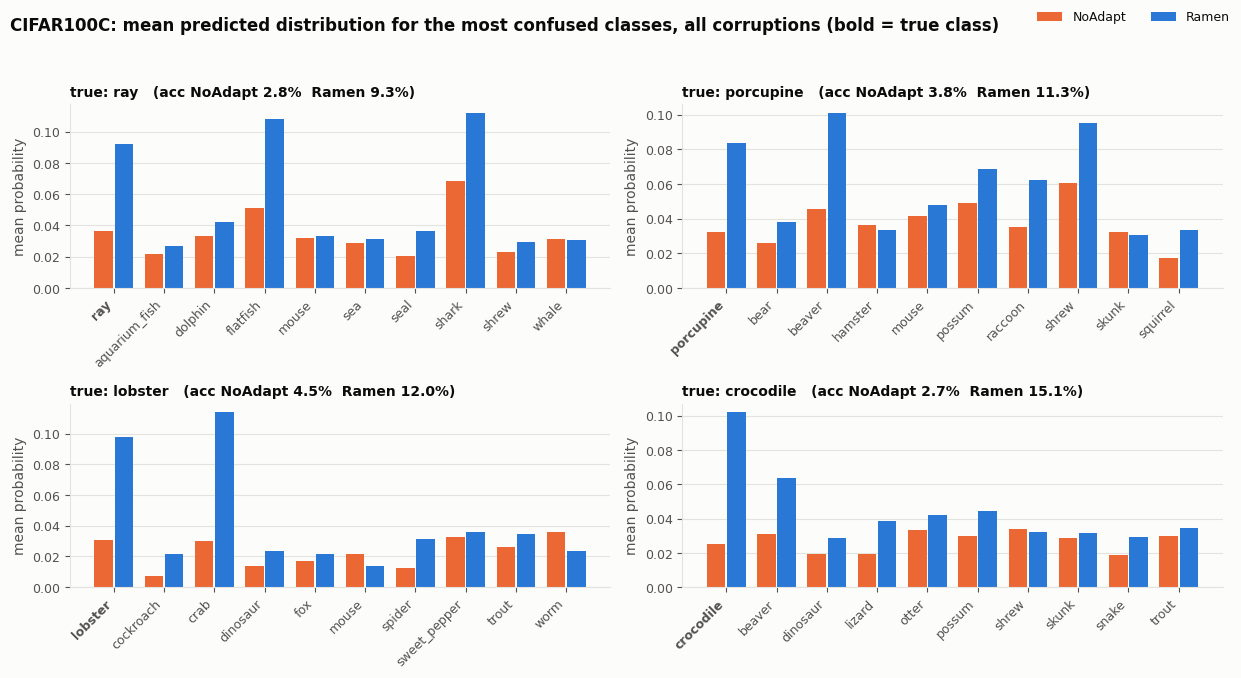

In [6]:
exp.plot_class_probs(n=4);

The highest-error classes above are near chance, so their mass is diffuse. The true classes of the top confused pairs are the ones where a single confuser takes most of the mass:

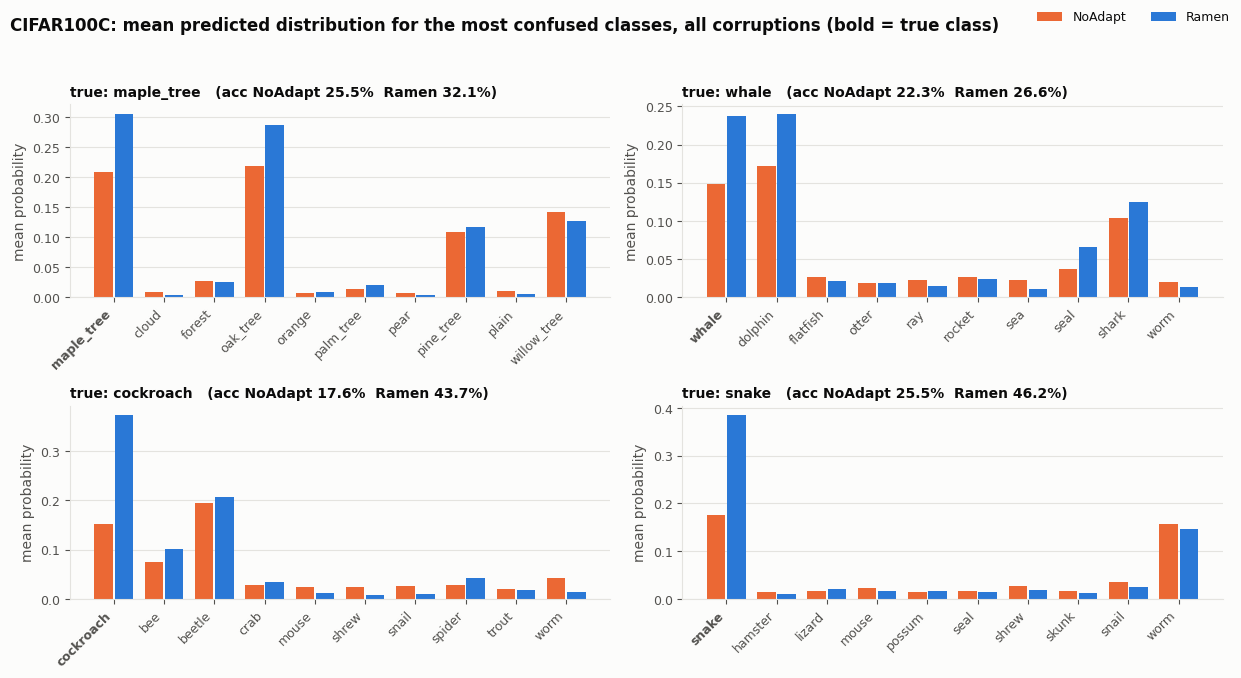

In [7]:
exp.plot_class_probs(classes=list(dict.fromkeys(a for a, _ in pairs.index))[:4]);

worst corruption for Ramen: glass_blur


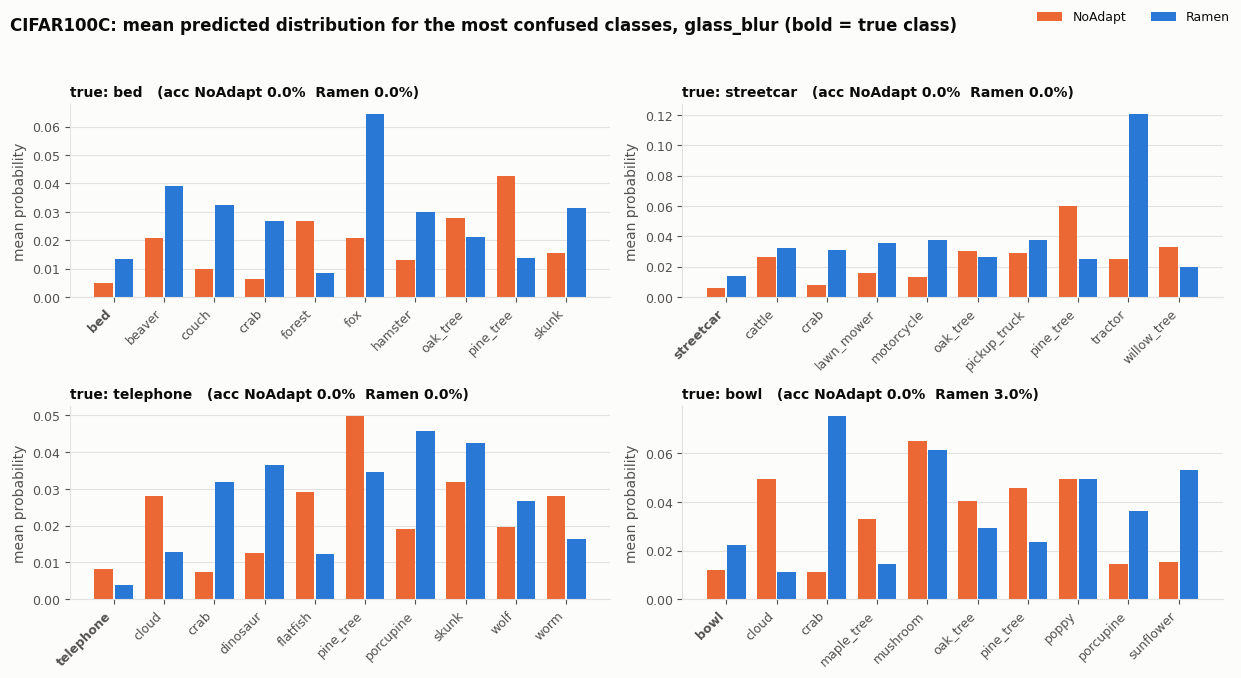

In [8]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst corruption for Ramen:', worst)
exp.plot_class_probs(domain=worst, n=4);

## 4. True class vs its confuser, per sample
The mean hides the spread. For each top confused pair (A → B), this is a histogram of `p(A) − p(B)` over the samples of true class A. Mass near 0 means the model is torn between the two. Mass far below 0 means it is confidently wrong.

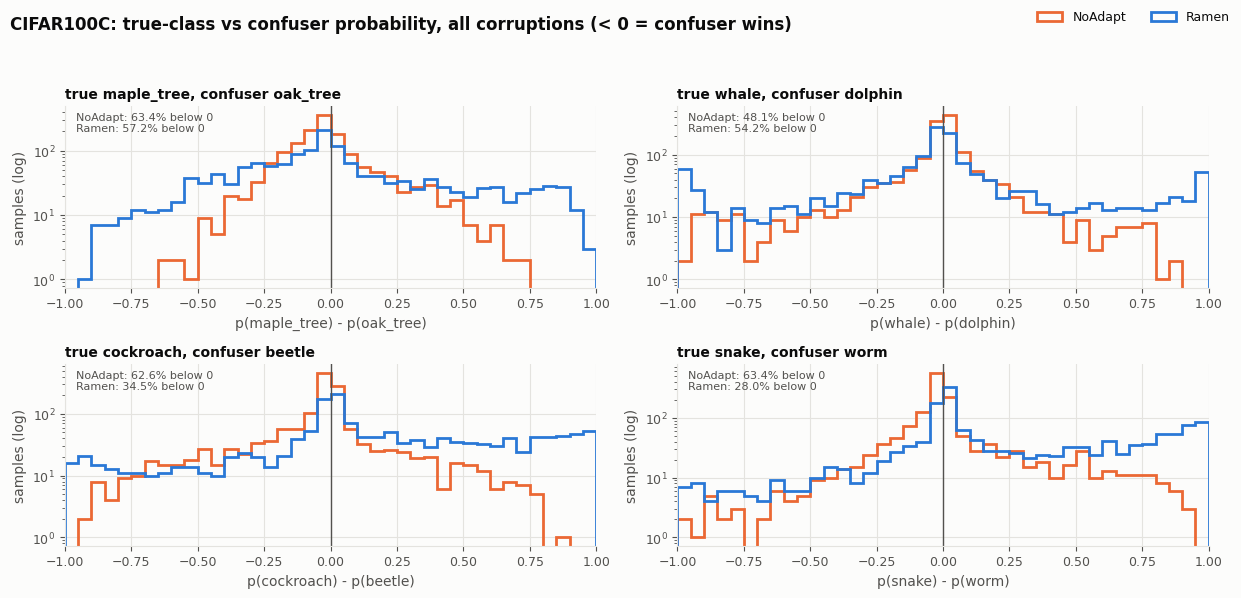

In [9]:
exp.plot_confusion_margin(top_k=4);

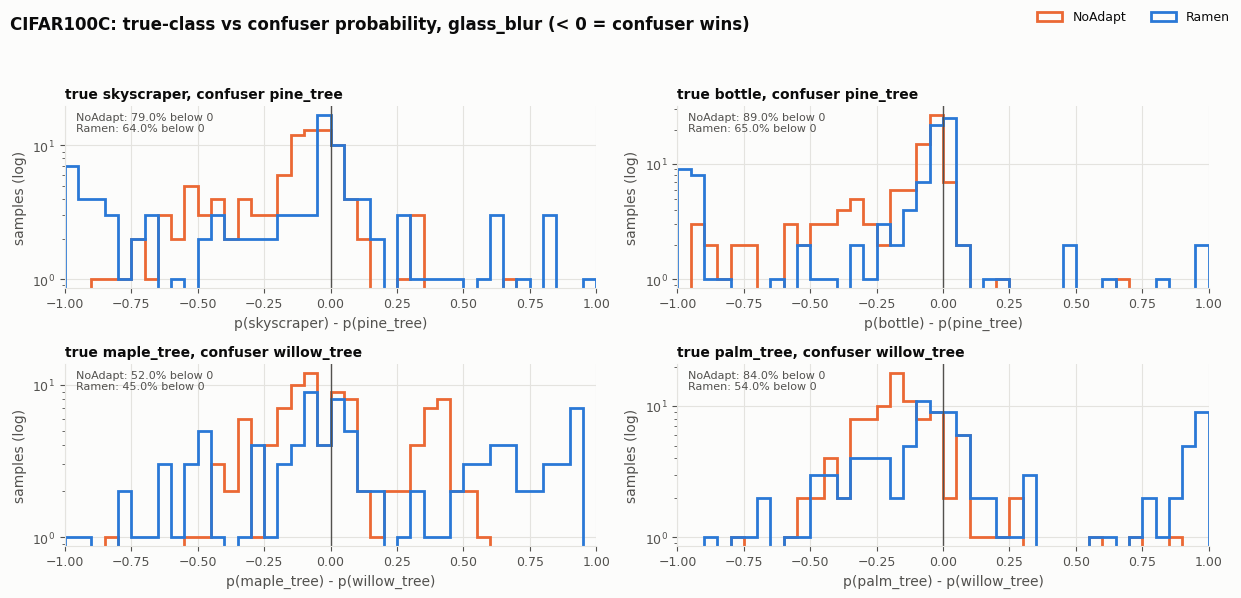

In [10]:
exp.plot_confusion_margin(domain=worst, top_k=4);

## 5. One failed image
A single test image next to both methods' predicted distribution (true class plus the 14 most probable others). By default `pick_failure` takes the top confused pair, keeps samples that NoAdapt got right but Ramen got wrong (`kind='broken'`), and returns the one Ramen is most confident on. Use `pair=(...)`, `kind='wrong'`, `domain=...` or `rank=1, 2, ...` to look at others.

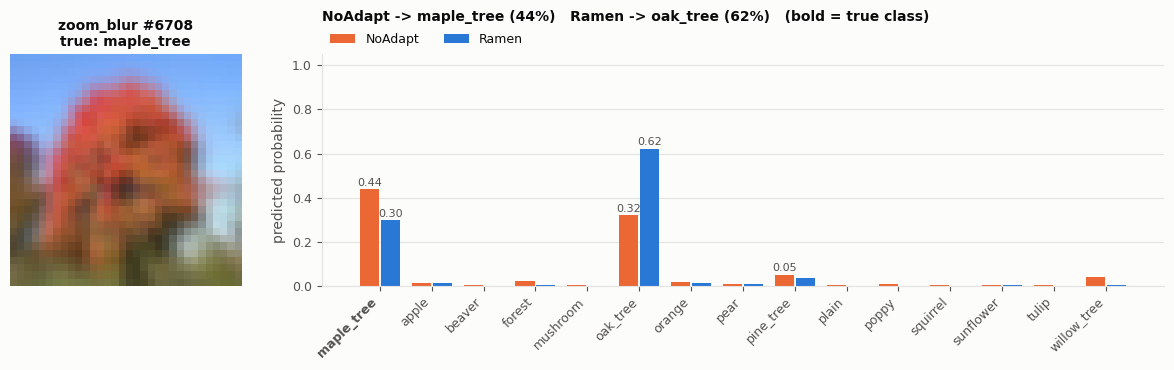

In [11]:
d_idx, s_idx = exp.pick_failure()   # e.g. exp.pick_failure(kind='wrong', rank=0)
exp.plot_sample_probs(d_idx, s_idx);